本笔记本从 2026-10-07 的 USD/SLE 收盘汇率出发，模拟随后一年的每日汇率路径。使用 [USDSLE1DICE.csv](../data/cleaned/USDSLE1DICE.csv) 中的 `close`，以历史对数收益率的均值和标准差校准模型，不加入宏观因子、AR 项或事件 dummy。汇率单位为 **SLE per USD**，数值上升表示利昂相对美元贬值。

选择对数差分：
    $$
    r_t=\ln\left(\frac{S_t}{S_{t-1}}\right)
    =\ln S_t-\ln S_{t-1}
    =\Delta\ln S_t
    $$
进行模拟，然后使用变化量和汇率数据还原为汇率水平。**正态分布是对每个更新日的对数收益率所作的假设；一年后的汇率水平理论上应该服从对数正态分布。** 

This notebook generates daily USD/SLE paths for the 12 months after 7 October 2026. It estimates a constant mean and volatility from the same close-price series, without factor regression. Gaussian log returns are compounded into positive FX levels. The terminal FX level has a lognormal distribution under these assumptions.


In [1]:
# import packages
from pathlib import Path
from statistics import NormalDist

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display


下面集中设置模拟次数、随机种子、预测起点及期限。默认使用 1,000 条独立路径，固定种子保证结果可以复现。预测期按 12 个日历月计算。

原始文件在周五、周六沿用上一日汇率，本次在这些日期将模拟收益率设为 0，其余日期抽取随机收益率，并输出每个日历日的汇率。

The constants define the path count, seed, forecast origin, and horizon. Friday and Saturday carry forward the previous simulated level, following this dataset's date convention. 


In [2]:
# set constants
N_SIMULATIONS = 1_000
RANDOM_SEED = 1145141919810
FORECAST_ORIGIN = pd.Timestamp("2026-10-07")
FORECAST_MONTHS = 12
CALIBRATION_START = pd.Timestamp("2022-07-19")
UNCHANGED_WEEKDAYS = (4, 5)  # pandas: Monday=0; Friday=4, Saturday=5
HISTOGRAM_BINS = 40

DATA_RELATIVE_PATH = Path("data/cleaned/USDSLE1DICE.csv")
FORECAST_END = FORECAST_ORIGIN + pd.DateOffset(months=FORECAST_MONTHS)

if N_SIMULATIONS < 2 or FORECAST_MONTHS < 1:
    raise ValueError("Use at least two paths and a positive forecast horizon.")
if CALIBRATION_START >= FORECAST_ORIGIN:
    raise ValueError("The calibration start must precede the forecast origin.")


下面读取 `close`，检查日期、缺失值与汇率正值，并在计算收益率之前截取截至预测起点的数据。起始汇率和校准收益率均取自同一个文件，避免混用其他文件的报价口径。本文件从 2022-07-19 开始，因此本次校准仅覆盖该日到 2026-10-07。

代码检查校准窗口的日历日期是否齐全，不补造缺失价格，也不修改 CSV。预测路径生成时不会使用起点之后的实际数据。

The data block validates dates and positive closes, then selects the historical window before computing returns. Both calibration returns and the initial FX level come from the same file. Its available history starts on 19 July 2022. No data files are written.


In [3]:
# load df and validate data
data_candidates = [DATA_RELATIVE_PATH, Path("..") / DATA_RELATIVE_PATH]
data_path = next((path for path in data_candidates if path.is_file()), None)
if data_path is None:
    raise FileNotFoundError("Run from the project root or the notebook directory.")

raw_prices = pd.read_csv(data_path)
if not {"date", "close"}.issubset(raw_prices.columns):
    raise ValueError("The input file must contain date and close columns.")

dates = pd.to_datetime(raw_prices["date"].astype(str), format="%Y%m%d", errors="raise")
prices = pd.Series(
    pd.to_numeric(raw_prices["close"], errors="raise").to_numpy(dtype=float),
    index=pd.DatetimeIndex(dates, name="date"),
    name="USD_SLE",
).sort_index()

if prices.index.has_duplicates or prices.index.hasnans:
    raise ValueError("Dates must be unique and non-missing.")
if not np.isfinite(prices.to_numpy()).all() or prices.le(0).any():
    raise ValueError("All close prices must be finite and strictly positive.")
if CALIBRATION_START not in prices.index or FORECAST_ORIGIN not in prices.index:
    raise ValueError("The calibration start and forecast origin must exist in the price file.")

calibration_prices = prices.loc[CALIBRATION_START:FORECAST_ORIGIN].copy()
expected_dates = pd.date_range(CALIBRATION_START, FORECAST_ORIGIN, freq="D")
if not calibration_prices.index.equals(expected_dates):
    raise ValueError("The calibration window contains missing calendar dates.")

# double check data source
initial_fx = float(calibration_prices.loc[FORECAST_ORIGIN])
data_summary = pd.DataFrame([{
    "calibration_start": calibration_prices.index.min().date(),
    "forecast_origin": FORECAST_ORIGIN.date(),
    "close_observations": len(calibration_prices),
    "initial_SLE_per_USD": initial_fx,
    "forecast_start": (FORECAST_ORIGIN + pd.Timedelta(days=1)).date(),
    "forecast_end": FORECAST_END.date(),
}])
display(data_summary)


,calibration_start,forecast_origin,close_observations,initial_SLE_per_USD,forecast_start,forecast_end
0,2022-07-19,2026-10-07,1542,22.92,2026-10-08,2027-10-07


下面计算日对数收益率。周五、周六按数据约定单独处理，其余日期保留全部收益，包括零值。每个更新日使用同一个均值 \(\hat\mu\) 和样本标准差：

$$
\hat\sigma
=
\sqrt{
\frac{1}{n-1}\sum_{t=1}^{n}(r_t-\hat\mu)^2
},
\qquad
\hat\mu=\frac{1}{n}\sum_{t=1}^{n}r_t.
$$

收益率以小数计量，例如 0.01 表示 1% 的对数变化。这里的μ hat是对数收益均值。表格同时列出最大绝对变动，方便判断波动率是否受到少数观察值影响；这些观察值全部保留。

The model uses the sample mean and standard deviation of log returns on update dates. Returns are in decimal units. Since the mean is estimated log returns. Large historical moves remain in the sample and are shown for context.


In [4]:
calendar_log_returns = np.log(calibration_prices).diff().dropna()
unchanged_history = calendar_log_returns.index.dayofweek.isin(UNCHANGED_WEEKDAYS)
if not np.allclose(
    calendar_log_returns.loc[unchanged_history].to_numpy(), 0.0, rtol=0.0, atol=1e-12
):
    raise ValueError("Historical carry-forward weekdays contain changes; review the calendar setting.")

calibration_returns = calendar_log_returns.loc[~unchanged_history].copy()
if len(calibration_returns) < 2:
    raise ValueError("At least two update-date returns are required.")

mu = float(calibration_returns.mean())
sigma = float(calibration_returns.std(ddof=1))
if not np.isfinite(sigma) or sigma <= 0:
    raise ValueError("A positive, finite volatility is required for this simulation.")

largest_move_date = calibration_returns.abs().idxmax()
calibration_summary = pd.DataFrame([{
    "update_return_observations": len(calibration_returns),
    "mean_log_return": mu,
    "std_log_return": sigma,
    "mean_log_return_pct": 100 * mu,
    "std_log_return_pct": 100 * sigma,
    "zero_return_share": float(calibration_returns.eq(0).mean()),
    "largest_move_date": largest_move_date.date(),
    "largest_log_return_pct": 100 * float(calibration_returns.loc[largest_move_date]),
}])
display(calibration_summary)

largest_dates = calibration_returns.abs().nlargest(5).index
largest_moves = pd.DataFrame({
    "previous_close": calibration_prices.shift(1).loc[largest_dates],
    "close": calibration_prices.loc[largest_dates],
    "log_return_pct": 100 * calibration_returns.loc[largest_dates],
}).rename_axis("date")
display(largest_moves)


,update_return_observations,mean_log_return,std_log_return,mean_log_return_pct,std_log_return_pct,zero_return_share,largest_move_date,largest_log_return_pct
0,1101,0.00047,0.015486,0.047006,1.548576,0.222525,2023-06-19,-24.686008


,previous_close,close,log_return_pct
date,,,
2023-06-19,22.40,17.50,-24.686008
2026-06-08,22.70,24.35,7.016693
2026-06-09,24.35,22.71,-6.972649
2026-05-20,24.35,22.74,-6.840636
2026-05-13,22.75,24.35,6.796670


下面对每条路径 \(j=1,\dots,M\)、每个更新日 \(t=1,\dots,T\) 独立抽取 \(z_{t,j}\sim N(0,1)\)，生成对数收益率 \(r_{t,j}=\hat\mu+\hat\sigma z_{t,j}\)，并累计还原汇率：

For each path \(j=1,\dots,M\) and each update date \(t=1,\dots,T\), draw independent \(z_{t,j}\sim N(0,1)\), generate the log-return \(r_{t,j}=\hat\mu+\hat\sigma z_{t,j}\), and reconstruct the exchange rate by accumulation:

$$
z_{t,j}\sim N(0,1),
\qquad
r_{t,j}=\hat\mu+\hat\sigma\,z_{t,j},
\qquad
S_{t,j}=S_0\exp\left(\sum_{u=1}^{t}r_{u,j}\right).
$$

In [5]:
forecast_dates = pd.date_range(
    FORECAST_ORIGIN + pd.Timedelta(days=1), FORECAST_END, freq="D"
)
update_mask = ~forecast_dates.dayofweek.isin(UNCHANGED_WEEKDAYS)
n_update_days = int(update_mask.sum())
if n_update_days < 1:
    raise ValueError("The forecast horizon must include at least one update date.")

rng = np.random.default_rng(RANDOM_SEED)
simulated_log_returns = np.zeros((len(forecast_dates), N_SIMULATIONS))
simulated_log_returns[update_mask, :] = rng.normal(
    loc=mu, scale=sigma, size=(n_update_days, N_SIMULATIONS)
)

cumulative_log_returns = np.vstack([
    np.zeros((1, N_SIMULATIONS)),
    np.cumsum(simulated_log_returns, axis=0),
])
path_dates = pd.DatetimeIndex([FORECAST_ORIGIN]).append(forecast_dates)
fx_paths = pd.DataFrame(
    initial_fx * np.exp(cumulative_log_returns),
    index=path_dates.rename("date"),
    columns=pd.Index(
        [f"path_{i + 1:04d}" for i in range(N_SIMULATIONS)], name="simulation"
    ),
)

if not np.isfinite(fx_paths.to_numpy()).all() or fx_paths.le(0).any().any():
    raise ValueError("Generated FX levels must remain finite and positive.")

path_quantiles = pd.DataFrame(
    np.quantile(fx_paths.to_numpy(), [0.05, 0.50, 0.95], axis=1).T,
    index=fx_paths.index,
    columns=["P05", "P50", "P95"],
)
terminal_fx = fx_paths.iloc[-1].rename("terminal_SLE_per_USD")

display(pd.DataFrame([{
    "paths": N_SIMULATIONS,
    "forecast_calendar_days": len(forecast_dates),
    "random_update_days": n_update_days,
    "carry_forward_days": int((~update_mask).sum()),
    "seed": RANDOM_SEED,
}]))


,paths,forecast_calendar_days,random_update_days,carry_forward_days,seed
0,1000,365,261,104,1145141919810


**第一张图展示全部模拟路径，并叠加各日的中位数与 5%、95% 分位数。**纵轴是还原后的 USD/SLE 汇率水平。分位线展示给定模型下的横截面分布；各日中位数连接而成的线不一定对应某一条实际抽样路径，5% 至 95% 区间也不代表整条路径有 90% 的概率始终位于其中。

**The first chart shows every simulated FX path, together with the pointwise median and 5th/95th percentiles.** The percentile bounds describe each date's marginal distribution, rather than simultaneous coverage of a complete path.


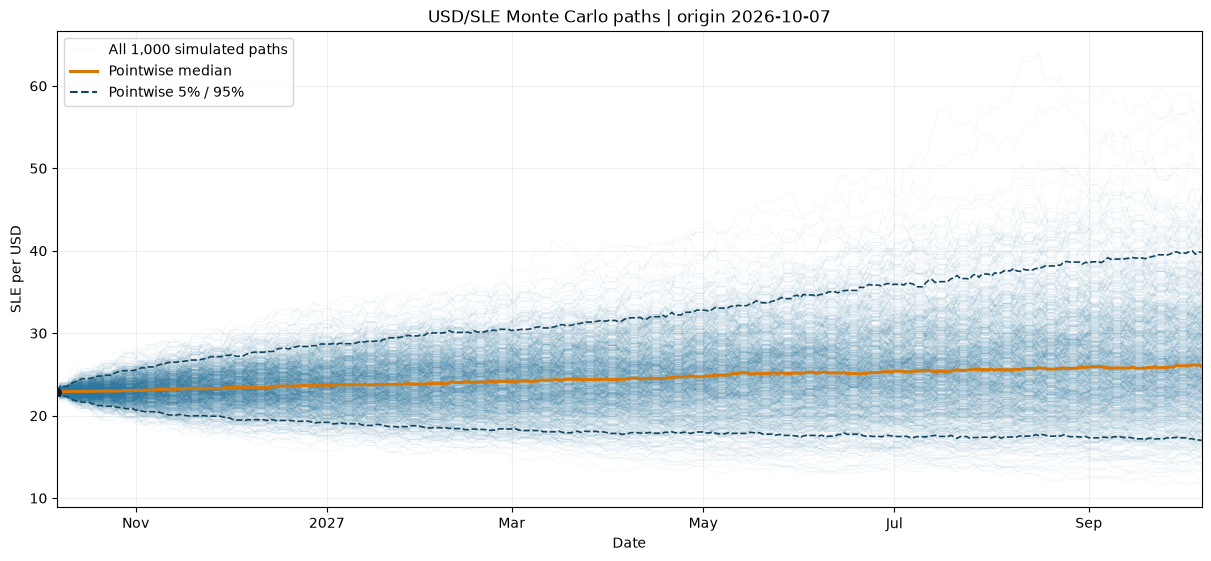

In [6]:
fig, ax = plt.subplots(figsize=(12, 5.5), layout="constrained")
path_lines = ax.plot(
    fx_paths.index, fx_paths.to_numpy(),
    color="#2878A3", alpha=0.055, linewidth=0.6,
)
path_lines[0].set_label(f"All {N_SIMULATIONS:,} simulated paths")
ax.plot(
    path_quantiles.index, path_quantiles["P50"],
    color="#D97706", linewidth=2.2, label="Pointwise median",
)
ax.plot(
    path_quantiles.index, path_quantiles[["P05", "P95"]],
    color="#16445B", linestyle="--", linewidth=1.2,
)
ax.plot([], [], color="#16445B", linestyle="--", label="Pointwise 5% / 95%")
ax.scatter([FORECAST_ORIGIN], [initial_fx], color="#111827", s=28, zorder=5)
ax.set(
    title=f"USD/SLE Monte Carlo paths | origin {FORECAST_ORIGIN:%Y-%m-%d}",
    xlabel="Date",
    ylabel="SLE per USD",
    xlim=(FORECAST_ORIGIN, FORECAST_END),
)
locator = mdates.AutoDateLocator(minticks=5, maxticks=9)
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
ax.grid(alpha=0.2)
ax.legend(loc="upper left")
plt.show()


第二张图展示一年后所有路径终点的密度直方图，叠加该模型的理论对数正态密度。

The second figure shows the density histogram of the endpoints of all paths one year later, with the theoretical log-normal density of this model superimposed.

,simulation_SLE_per_USD,theory_SLE_per_USD
Terminal date: 2027-10-07,,
Mean,26.9991,26.7355
Standard deviation,6.8811,6.7947
P05,17.0003,17.1704
Median (P50),26.0283,25.9117
P95,39.8118,39.1032


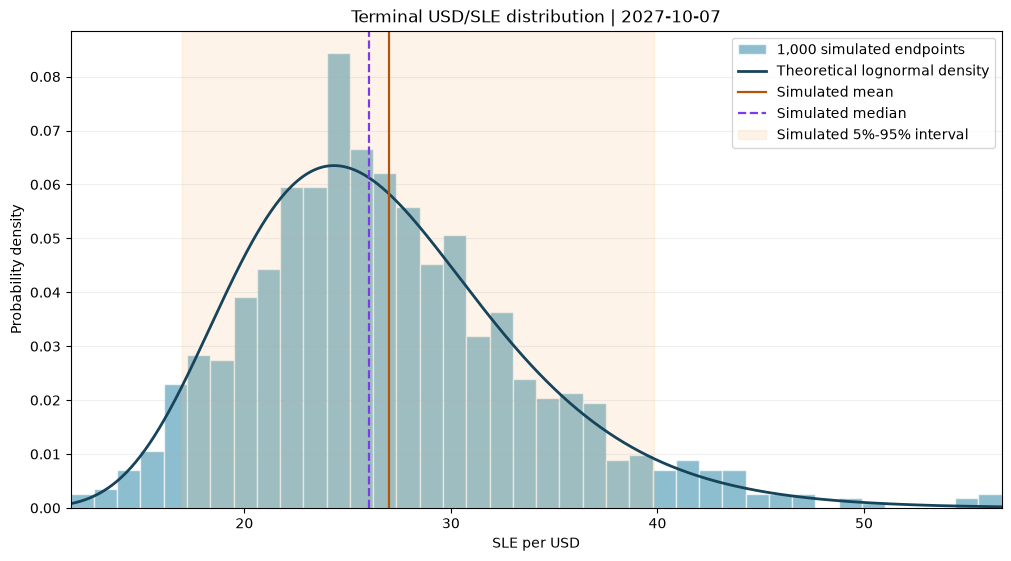

In [7]:
terminal_log_location = np.log(initial_fx) + n_update_days * mu
terminal_log_scale = np.sqrt(n_update_days) * sigma
terminal_log_variance = terminal_log_scale ** 2
normal_reference = NormalDist()

theoretical_mean = float(np.exp(terminal_log_location + terminal_log_variance / 2))
theoretical_std = float(np.sqrt(
    np.expm1(terminal_log_variance)
    * np.exp(2 * terminal_log_location + terminal_log_variance)
))
quantile_probabilities = [0.05, 0.50, 0.95]
theoretical_quantiles = np.exp(
    terminal_log_location
    + terminal_log_scale
    * np.array([normal_reference.inv_cdf(p) for p in quantile_probabilities])
)
simulation_quantiles = terminal_fx.quantile(quantile_probabilities).to_numpy()

terminal_summary = pd.DataFrame(
    {
        "simulation_SLE_per_USD": [
            terminal_fx.mean(), terminal_fx.std(ddof=1), *simulation_quantiles,
        ],
        "theory_SLE_per_USD": [
            theoretical_mean, theoretical_std, *theoretical_quantiles,
        ],
    },
    index=["Mean", "Standard deviation", "P05", "Median (P50)", "P95"],
)
terminal_summary.index.name = f"Terminal date: {FORECAST_END:%Y-%m-%d}"
display(terminal_summary.round(4))

theory_plot_bounds = np.exp(
    terminal_log_location
    + terminal_log_scale
    * np.array([normal_reference.inv_cdf(0.001), normal_reference.inv_cdf(0.999)])
)
density_grid = np.linspace(
    min(float(terminal_fx.min()), theory_plot_bounds[0]),
    max(float(terminal_fx.max()), theory_plot_bounds[1]),
    600,
)
theoretical_density = np.exp(
    -0.5 * ((np.log(density_grid) - terminal_log_location) / terminal_log_scale) ** 2
) / (density_grid * terminal_log_scale * np.sqrt(2 * np.pi))

fig, ax = plt.subplots(figsize=(10, 5.5), layout="constrained")
ax.hist(
    terminal_fx, bins=HISTOGRAM_BINS, density=True,
    color="#4F9CB7", alpha=0.65, edgecolor="white",
    label=f"{N_SIMULATIONS:,} simulated endpoints",
)
ax.plot(
    density_grid, theoretical_density,
    color="#16445B", linewidth=2, label="Theoretical lognormal density",
)
ax.axvline(
    float(terminal_fx.mean()), color="#B45309",
    linewidth=1.6, label="Simulated mean",
)
ax.axvline(
    float(simulation_quantiles[1]), color="#7C3AED",
    linestyle="--", linewidth=1.6, label="Simulated median",
)
ax.axvspan(
    simulation_quantiles[0], simulation_quantiles[2],
    color="#FDBA74", alpha=0.16, label="Simulated 5%-95% interval",
)
ax.set(
    title=f"Terminal USD/SLE distribution | {FORECAST_END:%Y-%m-%d}",
    xlabel="SLE per USD",
    ylabel="Probability density",
    xlim=(density_grid[0], density_grid[-1]),
)
ax.grid(axis="y", alpha=0.2)
ax.legend()
plt.show()


---

**三种宏观情景下的蒙特卡洛模拟 | Monte Carlo simulation under three macro scenarios**

在进行完无因子的蒙特卡洛模拟得到对照组之后，本节使用 [第 6 个 notebook](6_second_regression.ipynb) 的同期月度模型，将不同宏观假设转换为汇率路径。保留其截距、AR(1)、五个宏观因子和历史事件控制项的估计方式。第 6 个模型中 CPI 系数约为 1.0413，Holm 校正后显著；其余单项证据较弱。本节保留全部五个因子，展示给定假设下的模型反应，未来历史事件 dummy 设为 0。

After completing the factor-free Monte Carlo simulation to obtain the control group, this section uses the contemporaneous monthly model from [the sixth notebook](6_second_regression.ipynb) to translate different macroeconomic assumptions into exchange-rate paths. It retains the estimation approach for the intercept, AR(1), the five macroeconomic factors, and the historical-event controls. In the sixth model, the CPI coefficient is approximately 1.0413 and remains significant after Holm correction; the evidence for the other individual factors is weaker. This section retains all five factors to illustrate the model response under the given assumptions, with future historical-event dummies set to 0.


In [8]:
import statsmodels.api as scenario_sm
from statsmodels.stats.multitest import multipletests as scenario_multipletests

scenario_data_candidates = [
    Path("data/2_regression_monthly"),
    Path("../data/2_regression_monthly"),
]
scenario_data_dir = next((p for p in scenario_data_candidates if p.is_dir()), None)
if scenario_data_dir is None:
    raise FileNotFoundError("Cannot locate data/2_regression_monthly.")

scenario_training_calendar = pd.date_range("2012-01-31", "2024-12-31", freq="ME")
scenario_factor_files = {
    "CPI": "headline_cpi_log_change_monthly.csv",
    "GDP growth change": "gdp_annual_pct_change_monthly.csv",
    "Trade balance change": "trade_balance_annual_pct_change_monthly.csv",
    "FX reserves": "fx_reserves_log_change_monthly.csv",
    "Government debt / GDP": "general_government_gross_debt_annual_change_pp_monthly.csv",
}
scenario_factors = list(scenario_factor_files)

def scenario_read_monthly(filename, usecols=None):
    frame = pd.read_csv(scenario_data_dir / filename, usecols=usecols)
    frame.index = pd.to_datetime(frame.pop("date"))
    if frame.index.has_duplicates:
        raise ValueError(f"Duplicate monthly dates in {filename}.")
    return frame.reindex(scenario_training_calendar).astype(float)

scenario_macro_history = pd.DataFrame({
    name: scenario_read_monthly(filename, [0, 1]).iloc[:, 0]
    for name, filename in scenario_factor_files.items()
})
scenario_fx_history = scenario_read_monthly(
    "USDSLE_monthly.csv", [0, 1]
).iloc[:, 0].rename("fx_change")
scenario_event_history = scenario_read_monthly(
    "Sierra_Leone_Policy_Event_Dummies_monthly.csv"
)
scenario_sample = pd.concat([
    scenario_fx_history,
    scenario_fx_history.shift(1).rename("fx_lag1"),
    scenario_macro_history,
    scenario_event_history,
], axis=1).dropna()

scenario_event_groups = {}
for scenario_event_name in scenario_event_history:
    scenario_event_values = scenario_sample[scenario_event_name]
    if scenario_event_values.nunique() > 1:
        scenario_event_groups.setdefault(tuple(scenario_event_values), []).append(
            scenario_event_name
        )
scenario_policy_X = pd.DataFrame(index=scenario_sample.index)
for scenario_pattern in scenario_event_groups:
    scenario_event_month = scenario_sample.index[np.asarray(scenario_pattern) == 1][0]
    scenario_policy_X[f"P_{scenario_event_month:%Y_%m}"] = scenario_pattern

scenario_y = scenario_sample["fx_change"]
scenario_X = scenario_sm.add_constant(
    pd.concat([
        scenario_sample[["fx_lag1", *scenario_factors]], scenario_policy_X
    ], axis=1),
    has_constant="add",
)
scenario_fit = scenario_sm.OLS(scenario_y, scenario_X).fit()
scenario_hac = scenario_sm.OLS(scenario_y, scenario_X).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 12, "kernel": "bartlett", "use_correction": True},
    use_t=False,
)
scenario_beta = scenario_fit.params.copy()
# Residual variance uses SSE / residual degrees of freedom, in monthly 100*log units.
scenario_monthly_sigma = float(np.sqrt(scenario_fit.mse_resid))
scenario_continuous_terms = ["const", "fx_lag1", *scenario_factors]
scenario_coefficient_table = pd.DataFrame({
    "coefficient": scenario_beta.loc[scenario_continuous_terms],
    "p_HAC": scenario_hac.pvalues.loc[scenario_continuous_terms],
})
scenario_coefficient_table["p_Holm_5_factors"] = np.nan
scenario_coefficient_table.loc[scenario_factors, "p_Holm_5_factors"] = (
    scenario_multipletests(
        scenario_hac.pvalues.loc[scenario_factors], method="holm"
    )[1]
)
display(pd.DataFrame([{
    "sample_start": scenario_y.index.min().date(),
    "sample_end": scenario_y.index.max().date(),
    "n": int(scenario_fit.nobs),
    "parameters": len(scenario_beta),
    "R2": scenario_fit.rsquared,
    "residual_df": int(scenario_fit.df_resid),
    "monthly_residual_sigma_pct_log": scenario_monthly_sigma,
}]))
display(scenario_coefficient_table.round(6))


,sample_start,sample_end,n,parameters,R2,residual_df,monthly_residual_sigma_pct_log
0,2012-02-29,2024-12-31,155,12,0.532932,143,3.427865


,coefficient,p_HAC,p_Holm_5_factors
const,-0.026352,0.937887,NaN
fx_lag1,-0.162354,0.105030,NaN
CPI,1.041301,0.000601,0.003003
GDP growth change,-0.002104,0.272006,0.527862
Trade balance change,0.001154,0.085600,0.342399
FX reserves,-0.107443,0.115429,0.346286
Government debt / GDP,0.082791,0.263931,0.527862


设置三种压力假设：5%、20%、50% 分别对应低、高、极高年化通胀；“正常”为中间情景名称。GDP 共同参考增速为 4%，用于计算增长率变化。

| 未来一年假设 | 好于预期 | 正常高通胀 | 差情况 |
|---|---:|---:|---:|
| CPI 年化增幅 | 5% | 20% | 50% |
| 实际 GDP 年增速，参考值 4% | 6% | 4% | 1% |
| 贸易赤字幅度变化 | 缩小 20% | 不变 | 扩大 30% |
| 外汇储备增幅 | 20% | 0% | -25% |
| 政府债务/GDP 年度变化 | -3 个百分点 | 0 | +8 个百分点 |

转换使用第 6 个模型的单位：

- CPI 和储备：`100 * log1p(年度增幅 / 100) / 12`，得到月度对数变化。
- GDP：`100 * (情景增速 - 参考增速) / abs(参考增速)`。
- 贸易：`100 * (情景差额 - 参考差额) / abs(参考差额)`；以 -100 赤字指数为共同基点，缩小赤字产生正输入。保留原模型贸易系数为正的估计方向。
- 债务：年度债务比率变化的百分点数直接填入各月，与原回归一致。

每种情景的回归输入固定，独立模拟三批，每批沿用前文 `N_SIMULATIONS`。95% 区间取每个日期 2.5% 与 97.5% 分位数，为条件预测区间。


Set three researcher-specified stress assumptions: 5%, 20%, and 50% correspond to low, high, and very high annualized inflation, respectively; “normal” is the middle-scenario name. The common reference GDP growth is 4%, used to calculate growth-rate changes.

| Assumption for the next year | Better than expected | Normal high inflation | Adverse case |
|---|---:|---:|---:|
| CPI annualized increase | 5% | 20% | 50% |
| Real GDP annual growth, reference 4% | 6% | 4% | 1% |
| Change in trade deficit magnitude | Narrow by 20% | Unchanged | Widen by 30% |
| FX reserve increase | 20% | 0% | -25% |
| Annual change in government debt/GDP | -3 percentage points | 0 | +8 percentage points |

Conversions use the units of Model 6:

- CPI and reserves: `100 * log1p(annual increase / 100) / 12`, yielding monthly log changes.
- GDP: `100 * (scenario growth - reference growth) / abs(reference growth)`.
- Trade: `100 * (scenario balance - reference balance) / abs(reference balance)`; using a -100 deficit index as the common base, a smaller deficit produces a positive input. Retain the positive trade coefficient estimated in the original model.
- Debt: annual percentage-point changes in the debt ratio are entered directly for each month, consistent with the original regression.

For each scenario, keep regression inputs fixed and run three independent simulation batches, each using `N_SIMULATIONS` as above. The 95% interval uses the 2.5% and 97.5% quantiles for each date and represents a conditional forecast interval.

In [9]:
SCENARIO_RUNS = 3
SCENARIO_INTERVAL_LEVEL = 0.95
SCENARIO_GDP_REFERENCE_PCT = 4.0
SCENARIO_TRADE_REFERENCE_INDEX = -100.0

scenario_assumptions = pd.DataFrame.from_dict({
    "Better": {
        "inflation_annual_pct": 5.0, "gdp_growth_pct": 6.0,
        "trade_deficit_change_pct": -20.0,
        "reserves_annual_pct": 20.0, "debt_change_pp": -3.0,
    },
    "Normal": {
        "inflation_annual_pct": 20.0, "gdp_growth_pct": 4.0,
        "trade_deficit_change_pct": 0.0,
        "reserves_annual_pct": 0.0, "debt_change_pp": 0.0,
    },
    "Adverse": {
        "inflation_annual_pct": 50.0, "gdp_growth_pct": 1.0,
        "trade_deficit_change_pct": 30.0,
        "reserves_annual_pct": -25.0, "debt_change_pp": 8.0,
    },
}, orient="index").rename_axis("scenario")
if (scenario_assumptions[["inflation_annual_pct", "reserves_annual_pct"]] <= -100).any().any():
    raise ValueError("Annual CPI/reserve changes must exceed -100%.")
if SCENARIO_GDP_REFERENCE_PCT == 0 or SCENARIO_TRADE_REFERENCE_INDEX == 0:
    raise ValueError("GDP and trade reference values cannot be zero.")

scenario_macro_inputs = pd.DataFrame(index=scenario_assumptions.index)
scenario_macro_inputs["CPI"] = (
    100 * np.log1p(scenario_assumptions["inflation_annual_pct"] / 100) / 12
)
scenario_macro_inputs["GDP growth change"] = (
    100 * (scenario_assumptions["gdp_growth_pct"] - SCENARIO_GDP_REFERENCE_PCT)
    / abs(SCENARIO_GDP_REFERENCE_PCT)
)
scenario_trade_levels = SCENARIO_TRADE_REFERENCE_INDEX * (
    1 + scenario_assumptions["trade_deficit_change_pct"] / 100
)
scenario_macro_inputs["Trade balance change"] = (
    100 * (scenario_trade_levels - SCENARIO_TRADE_REFERENCE_INDEX)
    / abs(SCENARIO_TRADE_REFERENCE_INDEX)
)
scenario_macro_inputs["FX reserves"] = (
    100 * np.log1p(scenario_assumptions["reserves_annual_pct"] / 100) / 12
)
scenario_macro_inputs["Government debt / GDP"] = scenario_assumptions["debt_change_pp"]

# Contributions are monthly percentage log changes, before the path-dependent AR term.
scenario_factor_contributions = scenario_macro_inputs.mul(
    scenario_beta.loc[scenario_factors], axis="columns"
)
scenario_factor_contributions.insert(0, "const", float(scenario_beta["const"]))
scenario_factor_contributions["total_excluding_AR"] = scenario_factor_contributions.sum(axis=1)

display(scenario_assumptions)
display(scenario_macro_inputs.round(6))
display(scenario_factor_contributions.round(6))


,inflation_annual_pct,gdp_growth_pct,trade_deficit_change_pct,reserves_annual_pct,debt_change_pp
scenario,,,,,
Better,5.0,6.0,-20.0,20.0,-3.0
Normal,20.0,4.0,0.0,0.0,0.0
Adverse,50.0,1.0,30.0,-25.0,8.0


,CPI,GDP growth change,Trade balance change,FX reserves,Government debt / GDP
scenario,,,,,
Better,0.406585,50.0,20.0,1.519346,-3.0
Normal,1.519346,0.0,0.0,0.000000,0.0
Adverse,3.378876,-75.0,-30.0,-2.397351,8.0


,const,CPI,GDP growth change,Trade balance change,FX reserves,Government debt / GDP,total_excluding_AR
scenario,,,,,,,
Better,-0.026352,0.423377,-0.105209,0.023082,-0.163243,-0.248374,-0.096720
Normal,-0.026352,1.582097,-0.000000,0.000000,-0.000000,0.000000,1.555745
Adverse,-0.026352,3.518428,0.157814,-0.034623,0.257578,0.662331,4.535176


第 6 个模型用的是月度汇率变化，所以日路径也得按同样的频率口径来。下表列出每个自然月总共有多少个更新日，以及这次预测覆盖了多少个。预测窗口两头的月份只模拟落在窗口内的日期；周五、周六继续沿用前一个值。

起点是 2026-10-07，所以 AR 初值用同一来源 `close` 算出的 2026 年 9 月完整月收益；2026 年 10 月从月初到起点已经发生的收益单独保存，并加到 10 月末的 AR 状态里。模拟不会读取起点之后的实际汇率。第 6 个模型做历史估计时仍用它原来的月度汇率序列，而本节的价格起点和近期 AR 状态用的是前面指定的 USD/SLE `close`，也就是把旧样本估计出的关系套到当前报价序列上。

Model 6 is estimated on monthly exchange-rate changes, so the daily paths need to follow the same frequency convention. The table below lists, for each calendar month, the total number of update days and how many are covered by this forecast. For the months at the two ends of the forecast window, only dates inside the window are simulated; Fridays and Saturdays continue to carry forward the previous value.

The start date is 2026-10-07, so the initial AR value uses the full September 2026 monthly return computed from the same-source `close`; the return already observed in October 2026 up to the start date is stored separately and added to the end-of-October AR state. The simulation does not read actual exchange rates after the start date. The historical estimation for Model 6 still uses its original monthly exchange-rate series, while the price starting point and recent AR state in this section use the previously specified USD/SLE `close`. This step applies the relationship estimated from the old sample to the current quote series.

In [10]:
scenario_dates = forecast_dates.copy()
scenario_path_dates = fx_paths.index.copy()
scenario_periods = scenario_dates.to_period("M")
scenario_origin_period = FORECAST_ORIGIN.to_period("M")
scenario_origin_is_month_end = (
    FORECAST_ORIGIN == scenario_origin_period.end_time.normalize()
)
scenario_lag_period = (
    scenario_origin_period if scenario_origin_is_month_end else scenario_origin_period - 1
)
scenario_lag_end = scenario_lag_period.end_time.normalize()
scenario_lag_start = (scenario_lag_period - 1).end_time.normalize()
if not all(d in calibration_prices.index for d in [scenario_lag_start, scenario_lag_end]):
    raise ValueError("The previous full month requires two observed month-end closes.")

scenario_initial_lag_pct = float(
    100 * np.log(calibration_prices.loc[scenario_lag_end] / calibration_prices.loc[scenario_lag_start])
)
scenario_observed_mtd_pct = (
    0.0 if scenario_origin_is_month_end else
    float(100 * np.log(initial_fx / calibration_prices.loc[scenario_lag_end]))
)
scenario_calendar_rows = []
scenario_update_positions = {}
for scenario_period in scenario_periods.unique():
    scenario_full_dates = pd.date_range(
        scenario_period.start_time, scenario_period.end_time.normalize(), freq="D"
    )
    scenario_full_count = int(
        (~scenario_full_dates.dayofweek.isin(UNCHANGED_WEEKDAYS)).sum()
    )
    scenario_positions = np.flatnonzero(
        (scenario_periods == scenario_period)
        & ~scenario_dates.dayofweek.isin(UNCHANGED_WEEKDAYS)
    )
    scenario_update_positions[scenario_period] = scenario_positions
    scenario_calendar_rows.append({
        "month": scenario_period,
        "full_month_update_days": scenario_full_count,
        "simulated_update_days": len(scenario_positions),
        "month_weight": len(scenario_positions) / scenario_full_count,
        "known_MTD_pct_log": (
            scenario_observed_mtd_pct if scenario_period == scenario_origin_period else 0.0
        ),
    })
scenario_calendar_table = pd.DataFrame(scenario_calendar_rows).set_index("month")

display(pd.DataFrame([{
    "initial_SLE_per_USD": initial_fx,
    "lag_month": str(scenario_lag_period),
    "initial_lag_pct_log": scenario_initial_lag_pct,
    "known_origin_month_MTD_pct_log": scenario_observed_mtd_pct,
    "forecast_start": scenario_dates.min().date(),
    "forecast_end": scenario_dates.max().date(),
    "total_month_weight": scenario_calendar_table["month_weight"].sum(),
}]))
display(scenario_calendar_table.round(6))


,initial_SLE_per_USD,lag_month,initial_lag_pct_log,known_origin_month_MTD_pct_log,forecast_start,forecast_end,total_month_weight
0,22.92,2026-09,0.568556,-0.043621,2026-10-08,2027-10-07,12.0


,full_month_update_days,simulated_update_days,month_weight,known_MTD_pct_log
month,,,,
2026-10,21,16,0.761905,-0.043621
2026-11,22,22,1.000000,0.000000
2026-12,23,23,1.000000,0.000000
2027-01,21,21,1.000000,0.000000
2027-02,20,20,1.000000,0.000000
2027-03,23,23,1.000000,0.000000
2027-04,21,21,1.000000,0.000000
2027-05,22,22,1.000000,0.000000
2027-06,22,22,1.000000,0.000000


令 \(R_{m-1,j}\) 为第 \(j\) 条路径上一月的 \(100\times\log\) 变化，\(N_m\) 为当前整月的更新日数。对每个月，先计算条件均值，再将其分配到该月的更新日：

Let \(R_{m-1,j}\) be the `100 × log change` of the first month on the \(j\)th path, and \(N_m\) be the number of updated days for the current month. First, calculate the conditional mean for each month, and then distribute it to the updated days:

$$
M_{m,j}=a+\phi R_{m-1,j}+\beta^\top X_m,\qquad
r_{d,j}=\frac{M_{m,j}}{100N_m}
+\frac{\sigma_{\mathrm{res}}}{100\sqrt{N_m}}z_{d,j},
\quad z_{d,j}\sim N(0,1).
$$


In [11]:
def simulate_macro_scenario(factor_inputs, standard_shocks):
    """Generate calendar-day paths while preserving monthly regression moments."""
    if standard_shocks.shape != (len(scenario_dates), N_SIMULATIONS):
        raise ValueError("Unexpected shock matrix shape.")
    daily_returns = np.zeros_like(standard_shocks)
    previous_month_return = np.full(N_SIMULATIONS, scenario_initial_lag_pct)
    factor_effect = float(
        factor_inputs.loc[scenario_factors].to_numpy()
        @ scenario_beta.loc[scenario_factors].to_numpy()
    )
    monthly_states = {}
    monthly_means = {}
    for month, calendar_row in scenario_calendar_table.iterrows():
        positions = scenario_update_positions[month]
        full_count = int(calendar_row["full_month_update_days"])
        monthly_mean = (
            float(scenario_beta["const"])
            + float(scenario_beta["fx_lag1"]) * previous_month_return
            + factor_effect
        )
        daily_returns[positions, :] = (
            monthly_mean[None, :] / (100 * full_count)
            + scenario_monthly_sigma / (100 * np.sqrt(full_count))
            * standard_shocks[positions, :]
        )
        previous_month_return = (
            float(calendar_row["known_MTD_pct_log"])
            + 100 * daily_returns[positions, :].sum(axis=0)
        )
        monthly_means[month] = monthly_mean.copy()
        monthly_states[month] = previous_month_return.copy()

    log_paths = np.vstack([
        np.zeros((1, N_SIMULATIONS)), daily_returns.cumsum(axis=0)
    ])
    levels = initial_fx * np.exp(log_paths)
    if not np.isfinite(levels).all() or np.any(levels <= 0):
        raise ValueError("Scenario paths must be finite and positive.")
    return {
        "paths": pd.DataFrame(levels, index=scenario_path_dates),
        "daily_log_returns": daily_returns,
        "monthly_states_pct_log": monthly_states,
        "monthly_means_pct_log": monthly_means,
    }

scenario_seed_streams = np.random.SeedSequence(RANDOM_SEED).spawn(SCENARIO_RUNS)
scenario_results = {}
scenario_shocks = {}
for scenario_run_number, scenario_seed_stream in enumerate(scenario_seed_streams, start=1):
    scenario_generator = np.random.default_rng(scenario_seed_stream)
    scenario_batch_shocks = np.zeros((len(scenario_dates), N_SIMULATIONS))
    scenario_batch_shocks[update_mask, :] = scenario_generator.standard_normal(
        (n_update_days, N_SIMULATIONS)
    )
    scenario_shocks[scenario_run_number] = scenario_batch_shocks
    for scenario_name, scenario_inputs in scenario_macro_inputs.iterrows():
        scenario_results[(scenario_name, scenario_run_number)] = simulate_macro_scenario(
            scenario_inputs, scenario_batch_shocks
        )

scenario_lower_q = (1 - SCENARIO_INTERVAL_LEVEL) / 2
scenario_upper_q = 1 - scenario_lower_q
scenario_run_intervals = {
    key: pd.DataFrame(
        np.quantile(
            result["paths"].to_numpy(),
            [scenario_lower_q, 0.5, scenario_upper_q],
            axis=1,
        ).T,
        index=scenario_path_dates,
        columns=["P025", "Median", "P975"],
    )
    for key, result in scenario_results.items()
}
display(pd.DataFrame([{
    "scenarios": len(scenario_macro_inputs),
    "batches_per_scenario": SCENARIO_RUNS,
    "paths_per_batch": N_SIMULATIONS,
    "total_paths": len(scenario_results) * N_SIMULATIONS,
    "calendar_forecast_days": len(scenario_dates),
    "interval_level": SCENARIO_INTERVAL_LEVEL,
    "root_seed": RANDOM_SEED,
}]))


,scenarios,batches_per_scenario,paths_per_batch,total_paths,calendar_forecast_days,interval_level,root_seed
0,3,3,1000,9000,365,0.95,1145141919810


下面按情景分别作图，每幅图包含三次独立批次的结果。每个面板绘制全部路径、中位数和 **95% 条件预测区间（2.5%–97.5%）**，并统一纵轴以便比较。

Each scenario has a figure with three batch panels. Every panel shows all paths, the median, and the pointwise 95% conditional prediction interval. 


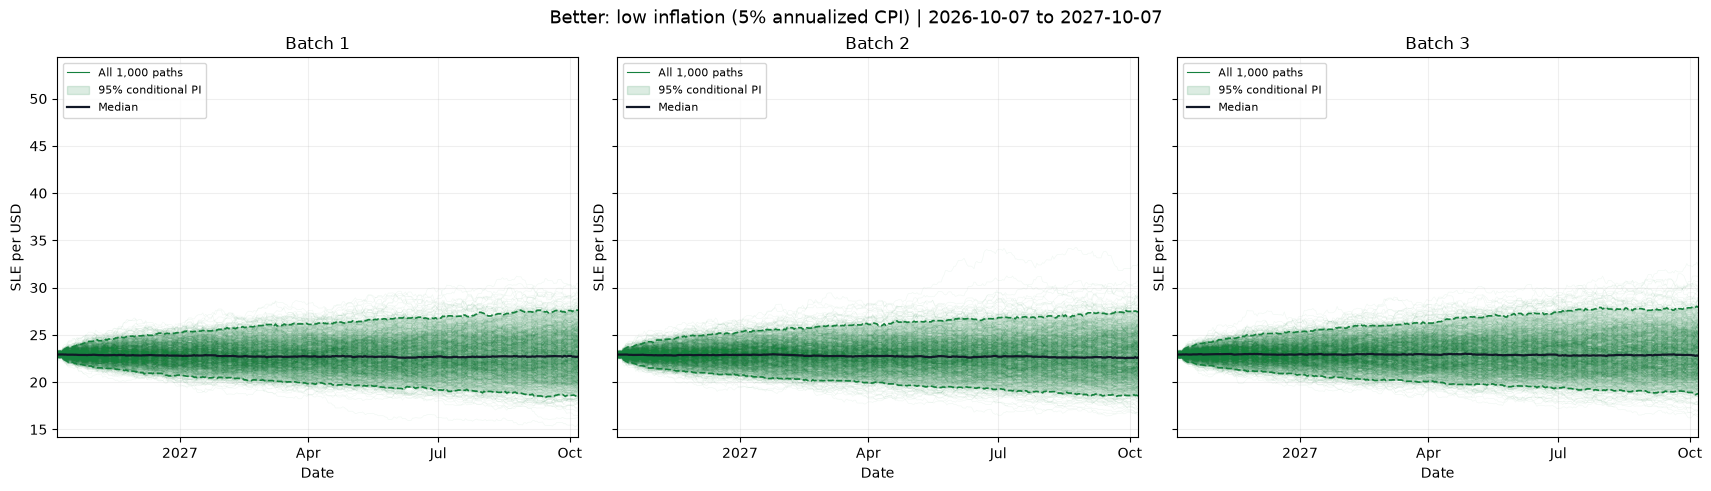

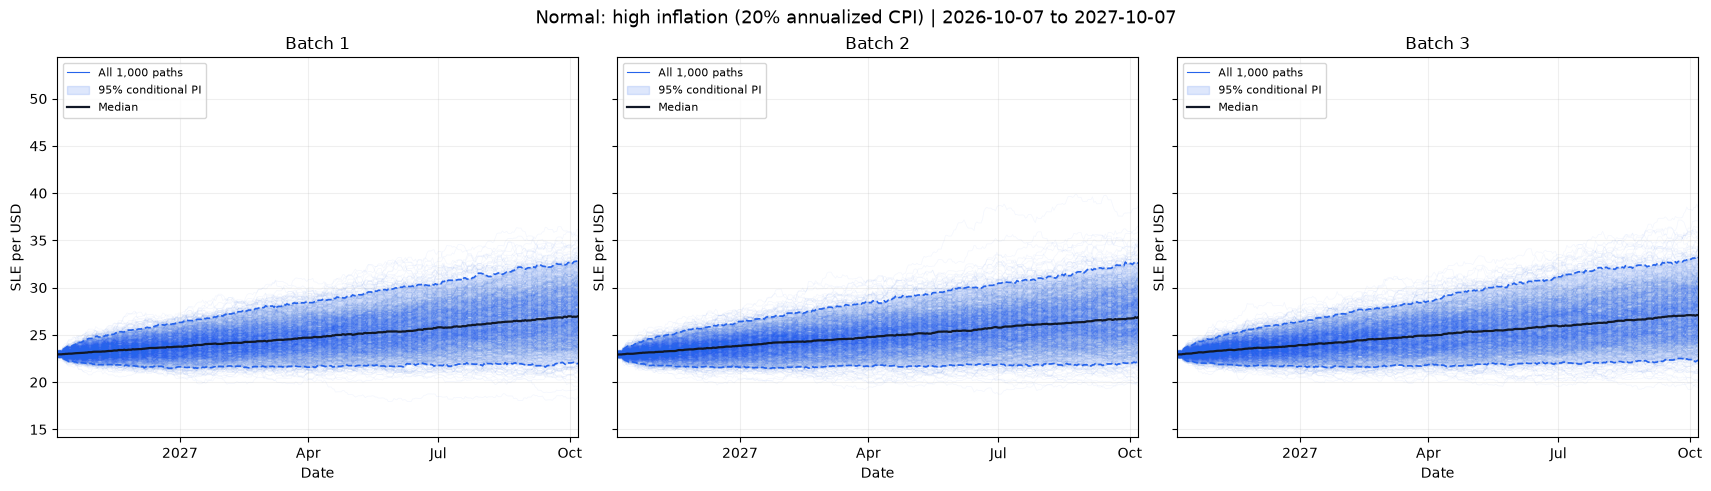

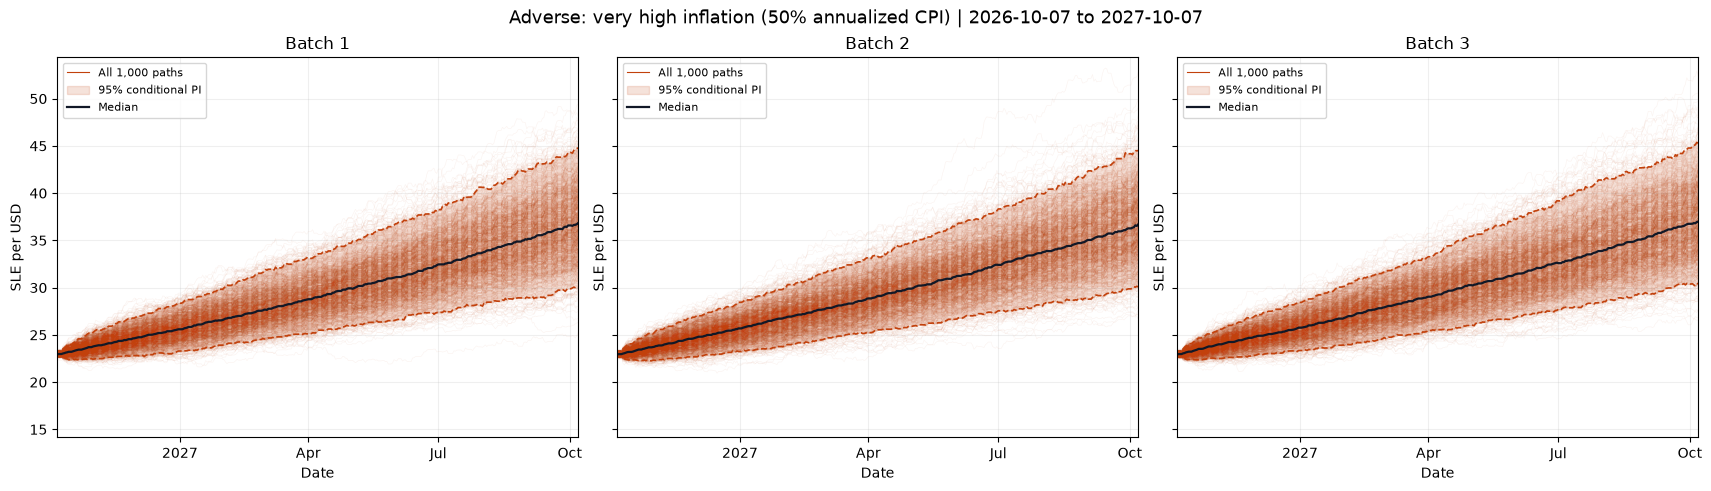

In [12]:
scenario_colors = {"Better": "#15803D", "Normal": "#2563EB", "Adverse": "#C2410C"}
scenario_titles = {
    "Better": "Better: low inflation",
    "Normal": "Normal: high inflation",
    "Adverse": "Adverse: very high inflation",
}
scenario_global_min = min(result["paths"].to_numpy().min() for result in scenario_results.values())
scenario_global_max = max(result["paths"].to_numpy().max() for result in scenario_results.values())
scenario_y_margin = 0.03 * (scenario_global_max - scenario_global_min)

for scenario_name in scenario_macro_inputs.index:
    scenario_fig, scenario_axes = plt.subplots(
        1, SCENARIO_RUNS, figsize=(17, 4.8),
        sharex=True, sharey=True, squeeze=False, layout="constrained",
    )
    for scenario_run_number, scenario_ax in enumerate(scenario_axes[0], start=1):
        scenario_key = (scenario_name, scenario_run_number)
        scenario_plot_paths = scenario_results[scenario_key]["paths"]
        scenario_band = scenario_run_intervals[scenario_key]
        scenario_color = scenario_colors[scenario_name]
        scenario_ax.plot(
            scenario_path_dates, scenario_plot_paths.to_numpy(),
            color=scenario_color, alpha=0.055, linewidth=0.5,
        )
        scenario_ax.plot(
            [], [], color=scenario_color, linewidth=0.8,
            label=f"All {N_SIMULATIONS:,} paths",
        )
        scenario_ax.fill_between(
            scenario_path_dates, scenario_band["P025"], scenario_band["P975"],
            color=scenario_color, alpha=0.15, label="95% conditional PI",
        )
        scenario_ax.plot(
            scenario_path_dates, scenario_band[["P025", "P975"]],
            color=scenario_color, linestyle="--", linewidth=1.2,
        )
        scenario_ax.plot(
            scenario_path_dates, scenario_band["Median"],
            color="#111827", linewidth=1.6, label="Median",
        )
        scenario_ax.set(
            title=f"Batch {scenario_run_number}",
            xlabel="Date", ylabel="SLE per USD",
            xlim=(FORECAST_ORIGIN, FORECAST_END),
            ylim=(scenario_global_min - scenario_y_margin, scenario_global_max + scenario_y_margin),
        )
        scenario_locator = mdates.AutoDateLocator(minticks=3, maxticks=5)
        scenario_ax.xaxis.set_major_locator(scenario_locator)
        scenario_ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(scenario_locator))
        scenario_ax.grid(alpha=0.2)
        scenario_ax.legend(fontsize=8, loc="upper left")
    scenario_inflation = scenario_assumptions.loc[scenario_name, "inflation_annual_pct"]
    scenario_fig.suptitle(
        f"{scenario_titles[scenario_name]} ({scenario_inflation:.0f}% annualized CPI)"
        f" | {FORECAST_ORIGIN:%Y-%m-%d} to {FORECAST_END:%Y-%m-%d}",
        fontsize=13,
    )
    plt.show()


下面列出每批的一年末统计量，再将**同一种情景**的三个独立批次合并，得到每种情景 3,000 条路径的汇总结果与对比图：

The end-of-year statistics for each batch are listed below. Then, the three independent batches of the **same scenario** are combined to obtain the summary results and comparison charts of 3,000 paths for each scenario:


,,paths,mean_SLE_per_USD,median_SLE_per_USD,P025_SLE_per_USD,P975_SLE_per_USD
scenario,batch,,,,,
Better,1,1000,22.8173,22.7051,18.4877,27.6102
Normal,1,1000,27.1154,26.9821,21.9702,32.8112
Adverse,1,1000,37.0132,36.8312,29.9899,44.7881
Better,2,1000,22.6756,22.6142,18.5505,27.4353
Normal,2,1000,26.9471,26.8741,22.0449,32.6033
Adverse,2,1000,36.7835,36.6838,30.0918,44.5043
Better,3,1000,22.9491,22.7958,18.7911,27.9295
Normal,3,1000,27.2721,27.0899,22.3308,33.1906
Adverse,3,1000,37.2271,36.9785,30.4822,45.3060


,paths,mean_SLE_per_USD,median_SLE_per_USD,P025_SLE_per_USD,P975_SLE_per_USD,median_FX_change_pct
scenario,,,,,,
Better,3000,22.8140,22.7034,18.6039,27.6569,-0.9451
Normal,3000,27.1115,26.9801,22.1084,32.8667,17.7141
Adverse,3000,37.0079,36.8285,30.1785,44.8639,60.6828


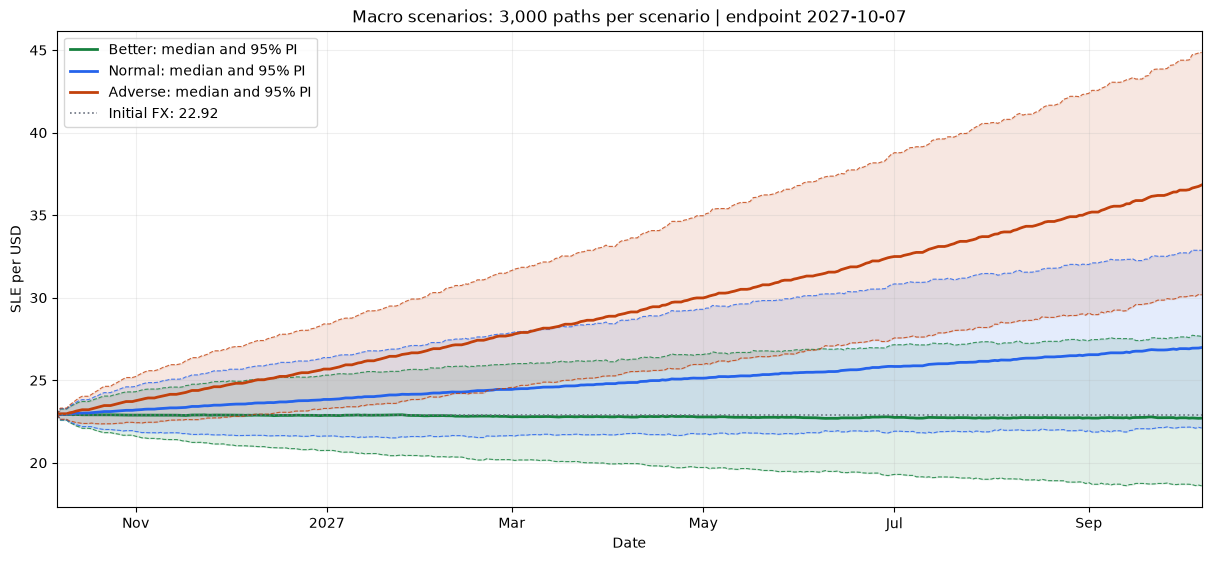

In [13]:
scenario_terminal_rows = []
for (scenario_name, scenario_run_number), scenario_result in scenario_results.items():
    scenario_terminal_values = scenario_result["paths"].iloc[-1]
    scenario_terminal_rows.append({
        "scenario": scenario_name,
        "batch": scenario_run_number,
        "paths": len(scenario_terminal_values),
        "mean_SLE_per_USD": scenario_terminal_values.mean(),
        "median_SLE_per_USD": scenario_terminal_values.median(),
        "P025_SLE_per_USD": scenario_terminal_values.quantile(scenario_lower_q),
        "P975_SLE_per_USD": scenario_terminal_values.quantile(scenario_upper_q),
    })
scenario_batch_summary = pd.DataFrame(scenario_terminal_rows).set_index(["scenario", "batch"])
display(scenario_batch_summary.round(4))

scenario_pooled_intervals = {}
scenario_pooled_rows = []
for scenario_name in scenario_macro_inputs.index:
    scenario_pooled_values = np.concatenate([
        scenario_results[(scenario_name, run)]["paths"].to_numpy()
        for run in range(1, SCENARIO_RUNS + 1)
    ], axis=1)
    scenario_pooled_band = pd.DataFrame(
        np.quantile(
            scenario_pooled_values, [scenario_lower_q, 0.5, scenario_upper_q], axis=1
        ).T,
        index=scenario_path_dates, columns=["P025", "Median", "P975"],
    )
    scenario_pooled_intervals[scenario_name] = scenario_pooled_band
    scenario_end_values = scenario_pooled_values[-1]
    scenario_pooled_rows.append({
        "scenario": scenario_name,
        "paths": len(scenario_end_values),
        "mean_SLE_per_USD": scenario_end_values.mean(),
        "median_SLE_per_USD": np.median(scenario_end_values),
        "P025_SLE_per_USD": np.quantile(scenario_end_values, scenario_lower_q),
        "P975_SLE_per_USD": np.quantile(scenario_end_values, scenario_upper_q),
        "median_FX_change_pct": 100 * (np.median(scenario_end_values) / initial_fx - 1),
    })
scenario_pooled_summary = pd.DataFrame(scenario_pooled_rows).set_index("scenario")
display(scenario_pooled_summary.round(4))

scenario_compare_fig, scenario_compare_ax = plt.subplots(figsize=(12, 5.5), layout="constrained")
for scenario_name, scenario_band in scenario_pooled_intervals.items():
    scenario_color = scenario_colors[scenario_name]
    scenario_compare_ax.fill_between(
        scenario_path_dates, scenario_band["P025"], scenario_band["P975"],
        color=scenario_color, alpha=0.12,
    )
    scenario_compare_ax.plot(
        scenario_path_dates, scenario_band[["P025", "P975"]],
        color=scenario_color, linestyle="--", linewidth=0.8, alpha=0.8,
    )
    scenario_compare_ax.plot(
        scenario_path_dates, scenario_band["Median"],
        color=scenario_color, linewidth=2,
        label=f"{scenario_name}: median and 95% PI",
    )
scenario_compare_ax.axhline(
    initial_fx, color="#6B7280", linestyle=":", linewidth=1.2,
    label=f"Initial FX: {initial_fx:.2f}",
)
scenario_compare_ax.set(
    title=f"Macro scenarios: {SCENARIO_RUNS * N_SIMULATIONS:,} paths per scenario"
          f" | endpoint {FORECAST_END:%Y-%m-%d}",
    xlabel="Date", ylabel="SLE per USD", xlim=(FORECAST_ORIGIN, FORECAST_END),
)
scenario_compare_locator = mdates.AutoDateLocator(minticks=5, maxticks=8)
scenario_compare_ax.xaxis.set_major_locator(scenario_compare_locator)
scenario_compare_ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(scenario_compare_locator))
scenario_compare_ax.grid(alpha=0.2)
scenario_compare_ax.legend(loc="upper left")
plt.show()


---

**检验性回测一年期回测：预测 2025 年 | 1-year Testing Regression**

最后，笔记本将使用2022-Jul到2024-Dec的数据建立一个随机模型，然后预测2025年的全年汇率变化，也就是第二次POS，用于验证模型预测可行性。主要分为几个步骤：
1. 准备数据，切分数据，并计算漂移率和波动率
2. 蒙特卡洛模拟历史漂移模型和零对数漂移模型
3. 使用真实的25年汇率数据，进行对比
4. 计算RMSE和MAE，估计均值和中位数距离真实值多远
5. 计算蒙特卡洛的路径的置信区间（也就是CI）

本节检查前半部分无宏观因子的随机模型在历史一年中的预测表现。起点设为 **2024-12-31**，使用 **2022-07-19 至 2024-12-31** 的汇率估计参数，预测 **2025-01-01 至 2025-12-31** 的每日路径。预测期间不使用新观察到的汇率更新参数或路径。

Finally, the notebook will use data from 2022-Jul to 2024-Dec to build a stochastic model, and then forecast the full-year 2025 exchange rate changes to validate the feasibility of the model forecasts. This mainly consists of the following steps:

1. Prepare and split the data, and calculate the drift rate and volatility.
2. Run Monte Carlo simulations for the historical drift model and the zero log drift model.
3. Compare the simulations with the actual 2025 exchange rate data.
4. Compute RMSE and MAE to estimate how far the mean and median are from the actual values.
5. Compute the confidence intervals (CIs) for the Monte Carlo paths.

This section examines the forecasting performance of the stochastic model without macroeconomic factors from the first half over a one-year historical period. The starting point is set to **2024-12-31**; exchange rates from **2022-07-19 to 2024-12-31** are used to estimate the parameters, and the daily path from **2025-01-01 to 2025-12-31** is forecast. During the forecast period, newly observed exchange rates are not used to update the parameters or the path.

In [14]:
# import packages and set constants
from pathlib import Path
from statistics import NormalDist

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display, Markdown

BT_ORIGIN = pd.Timestamp("2024-12-31")
BT_CALIBRATION_START = pd.Timestamp("2022-07-19")
BT_END = BT_ORIGIN + pd.DateOffset(months=12)
BT_N_PATHS = 1_000
BT_SEED = 1145141919810
BT_UNCHANGED_WEEKDAYS = (4, 5)
BT_INTERVAL_LEVEL = 0.90

In [15]:

# load and validate backtest data
bt_candidates = [
    Path("data/cleaned/USDSLE1DICE.csv"),
    Path("../data/cleaned/USDSLE1DICE.csv"),
]
bt_data_path = next((bt_p for bt_p in bt_candidates if bt_p.is_file()), None)
if bt_data_path is None:
    raise FileNotFoundError("Run from the project root or notebook directory.")

bt_raw = pd.read_csv(bt_data_path)
if not {"date", "close"}.issubset(bt_raw.columns):
    raise ValueError("The input file must contain date and close.")
bt_raw_dates = pd.DatetimeIndex(
    pd.to_datetime(bt_raw["date"].astype(str), format="%Y%m%d")
)
if bt_raw_dates.has_duplicates or bt_raw_dates.isna().any():
    raise ValueError("Input dates must be unique and non-missing.")
bt_source = bt_raw.set_index(pd.DatetimeIndex(bt_raw_dates, name="date")).sort_index()
bt_train = pd.to_numeric(
    bt_source.loc[BT_CALIBRATION_START:BT_ORIGIN, "close"], errors="raise"
).astype(float)
bt_train_dates = pd.date_range(BT_CALIBRATION_START, BT_ORIGIN, freq="D")
if not bt_train.index.equals(bt_train_dates):
    raise ValueError("The training window must contain every calendar date.")
if not np.isfinite(bt_train.to_numpy()).all() or bt_train.le(0).any():
    raise ValueError("Training closes must be finite and positive.")

bt_initial_fx = float(bt_train.loc[BT_ORIGIN])
bt_dates = pd.date_range(BT_ORIGIN + pd.Timedelta(days=1), BT_END, freq="D")
display(pd.DataFrame([{
    "training_start": bt_train.index.min().date(),
    "training_end": bt_train.index.max().date(),
    "training_prices": len(bt_train),
    "initial_SLE_per_USD": bt_initial_fx,
    "forecast_start": bt_dates.min().date(),
    "forecast_end": bt_dates.max().date(),
    "forecast_calendar_days": len(bt_dates),
}]))


,training_start,training_end,training_prices,initial_SLE_per_USD,forecast_start,forecast_end,forecast_calendar_days
0,2022-07-19,2024-12-31,897,22.69,2025-01-01,2025-12-31,365


下面重新估计本次回测的 μ_hat 和 σ_hat 。

Next, re-estimate μ_hat and σ_hat for this backtest.

In [16]:
bt_calendar_returns = np.log(bt_train).diff().dropna()
bt_history_carry = bt_calendar_returns.index.dayofweek.isin(BT_UNCHANGED_WEEKDAYS)
if not np.allclose(
    bt_calendar_returns.loc[bt_history_carry].to_numpy(),
    0.0, rtol=0.0, atol=1e-12,
):
    raise ValueError("Training data do not match the carry-forward calendar.")

bt_returns = bt_calendar_returns.loc[~bt_history_carry].copy()
if len(bt_returns) < 2:
    raise ValueError("At least two update-date returns are required.")
bt_mu = float(bt_returns.mean())
bt_sigma = float(bt_returns.std(ddof=1))
if not np.isfinite([bt_mu, bt_sigma]).all() or bt_sigma <= 0:
    raise ValueError("Calibration requires finite drift and positive volatility.")

bt_update_mask = ~bt_dates.dayofweek.isin(BT_UNCHANGED_WEEKDAYS)
bt_update_counts = np.concatenate([[0], np.cumsum(bt_update_mask)])
bt_path_dates = pd.DatetimeIndex([BT_ORIGIN]).append(bt_dates)
bt_drifts = {"Historical drift": bt_mu, "Zero log drift": 0.0}

display(pd.DataFrame([{
    "training_update_returns": len(bt_returns),
    "mean_log_return_per_update": bt_mu,
    "std_log_return_per_update": bt_sigma,
    "mean_log_return_pct": 100 * bt_mu,
    "std_log_return_pct": 100 * bt_sigma,
    "forecast_update_days": int(bt_update_mask.sum()),
    "forecast_carry_forward_days": int((~bt_update_mask).sum()),
}]))


,training_update_returns,mean_log_return_per_update,std_log_return_per_update,mean_log_return_pct,std_log_return_pct,forecast_update_days,forecast_carry_forward_days
0,640,0.000793,0.012353,0.079289,1.235293,261,104


下面为两种模型生成同一组正态随机数，再分别加入各自的漂移。所有路径从同一个汇率出发。周五、周六沿用前一天的模拟值。

For the two models below, generate the same set of normal random numbers, then add their respective drifts separately. All paths start from the same exchange rate. Friday and Saturday carry forward the previous day's simulated values.

In [17]:
bt_rng = np.random.default_rng(BT_SEED)
bt_shocks = np.zeros((len(bt_dates), BT_N_PATHS))
bt_shocks[bt_update_mask, :] = bt_rng.standard_normal(
    (int(bt_update_mask.sum()), BT_N_PATHS)
)
bt_paths = {}
for bt_model, bt_drift in bt_drifts.items():
    bt_daily_returns = (
        bt_sigma * bt_shocks + bt_update_mask[:, None] * bt_drift
    )
    bt_log_paths = np.vstack([
        np.zeros((1, BT_N_PATHS)),
        np.cumsum(bt_daily_returns, axis=0),
    ])
    bt_levels = bt_initial_fx * np.exp(bt_log_paths)
    if not np.isfinite(bt_levels).all() or np.any(bt_levels <= 0):
        raise ValueError("Simulated FX levels must be finite and positive.")
    np.testing.assert_allclose(bt_levels[0], bt_initial_fx)
    np.testing.assert_allclose(
        bt_levels[1:][~bt_update_mask],
        bt_levels[:-1][~bt_update_mask],
        rtol=0.0, atol=0.0,
    )
    bt_paths[bt_model] = pd.DataFrame(bt_levels, index=bt_path_dates)

display(pd.DataFrame([
    {
        "model": bt_model,
        "paths": bt_frame.shape[1],
        "calendar_days_excluding_origin": len(bt_frame) - 1,
        "drift_per_update": bt_drifts[bt_model],
        "volatility_per_update": bt_sigma,
        "seed": BT_SEED,
    }
    for bt_model, bt_frame in bt_paths.items()
]).set_index("model"))


,paths,calendar_days_excluding_origin,drift_per_update,volatility_per_update,seed
model,,,,,
Historical drift,1000,365,0.000793,0.012353,1145141919810
Zero log drift,1000,365,0.000000,0.012353,1145141919810


**计算均值、中位数和预测区间 | Mean, median and prediction interval**

设 \(k\) 为起点以后累计的更新日数量，\(m\) 为对应模型的漂移：

Let \(k\) be the cumulative number of update days after the starting point, and let \(m\) be the drift of the corresponding model:

$$
\mathrm{Median}_k=S_0e^{km},\qquad
\mathrm{Mean}_k=S_0e^{km+k\hat\sigma^2/2},\qquad
Q_p(k)=S_0e^{km+\sqrt{k}\hat\sigma\Phi^{-1}(p)}.
$$

这里的 90% 预测区间取 5% 和 95% 分位数。路径仍由上一步的模拟生成，均值、中位数和区间线由上述公式计算。零对数漂移下，中位数保持起点水平，汇率均值会随期限上升。因此，零漂移模型的中位数与“汇率保持不变”基准相同。

The 90% prediction interval is taken as the 5% and 95% quantiles. The paths are still generated by the simulation in the previous step, while the mean, median, and interval lines are calculated using the formulas above. Under zero log drift, the median remains at the starting level, while the mean exchange rate rises with the horizon. Therefore, the median of the zero-drift model is the same as the “exchange rate remains unchanged” benchmark.

In [18]:
bt_alpha = 1 - BT_INTERVAL_LEVEL
bt_normal = NormalDist()
bt_z_lower = bt_normal.inv_cdf(bt_alpha / 2)
bt_z_upper = bt_normal.inv_cdf(1 - bt_alpha / 2)
bt_log_scale = bt_sigma * np.sqrt(bt_update_counts)
bt_distribution = {}
bt_terminal_rows = []

for bt_model, bt_drift in bt_drifts.items():
    bt_log_location = np.log(bt_initial_fx) + bt_drift * bt_update_counts
    bt_distribution[bt_model] = pd.DataFrame({
        "mean": np.exp(bt_log_location + 0.5 * bt_log_scale ** 2),
        "median": bt_initial_fx * np.exp(bt_drift * bt_update_counts),
        "lower": np.exp(bt_log_location + bt_z_lower * bt_log_scale),
        "upper": np.exp(bt_log_location + bt_z_upper * bt_log_scale),
    }, index=bt_path_dates)
    bt_terminal_sim = bt_paths[bt_model].iloc[-1]
    bt_terminal_exact = bt_distribution[bt_model].iloc[-1]
    bt_terminal_rows.append({
        "model": bt_model,
        "simulated_mean": bt_terminal_sim.mean(),
        "analytic_mean": bt_terminal_exact["mean"],
        "simulated_median": bt_terminal_sim.median(),
        "analytic_median": bt_terminal_exact["median"],
        "analytic_P05": bt_terminal_exact["lower"],
        "analytic_P95": bt_terminal_exact["upper"],
    })

bt_constant_forecast = pd.Series(bt_initial_fx, index=bt_dates, name="Constant FX")
np.testing.assert_array_equal(
    bt_distribution["Zero log drift"].loc[bt_dates, "median"].to_numpy(),
    bt_constant_forecast.to_numpy(),
)
display(pd.DataFrame(bt_terminal_rows).set_index("model").round(4))


,simulated_mean,analytic_mean,simulated_median,analytic_median,analytic_P05,analytic_P95
model,,,,,,
Historical drift,28.6916,28.4681,28.0069,27.9068,20.0978,38.7500
Zero log drift,23.3281,23.1464,22.7714,22.6900,16.3408,31.5062


现在两个模型的全年预测已完成。下面读取 2025 年的实际汇率，并检查评分日期是否完整。

The full-year forecasts for both models are now complete. Next, load the actual 2025 exchange rates and check whether the scoring dates are complete.

In [19]:
bt_actual = pd.to_numeric(
    bt_source.loc[bt_dates.min():BT_END, "close"], errors="raise"
).astype(float).rename("Actual FX")
if not bt_actual.index.equals(bt_dates):
    raise ValueError("The scoring window must contain every forecast date.")
if not np.isfinite(bt_actual.to_numpy()).all() or bt_actual.le(0).any():
    raise ValueError("Actual FX values must be finite and positive.")
assert bt_train.index.max() < bt_actual.index.min()
assert len(bt_train.index.intersection(bt_actual.index)) == 0

bt_actual_with_origin = pd.concat([
    pd.Series([bt_initial_fx], index=pd.DatetimeIndex([BT_ORIGIN])),
    bt_actual,
])
display(pd.DataFrame([{
    "scored_days": len(bt_actual),
    "actual_min_SLE_per_USD": bt_actual.min(),
    "actual_max_SLE_per_USD": bt_actual.max(),
    "actual_year_end_SLE_per_USD": bt_actual.iloc[-1],
    "origin_in_score": BT_ORIGIN in bt_actual.index,
}]))


,scored_days,actual_min_SLE_per_USD,actual_max_SLE_per_USD,actual_year_end_SLE_per_USD,origin_in_score
0,365,21.8,23.75,22.71,False


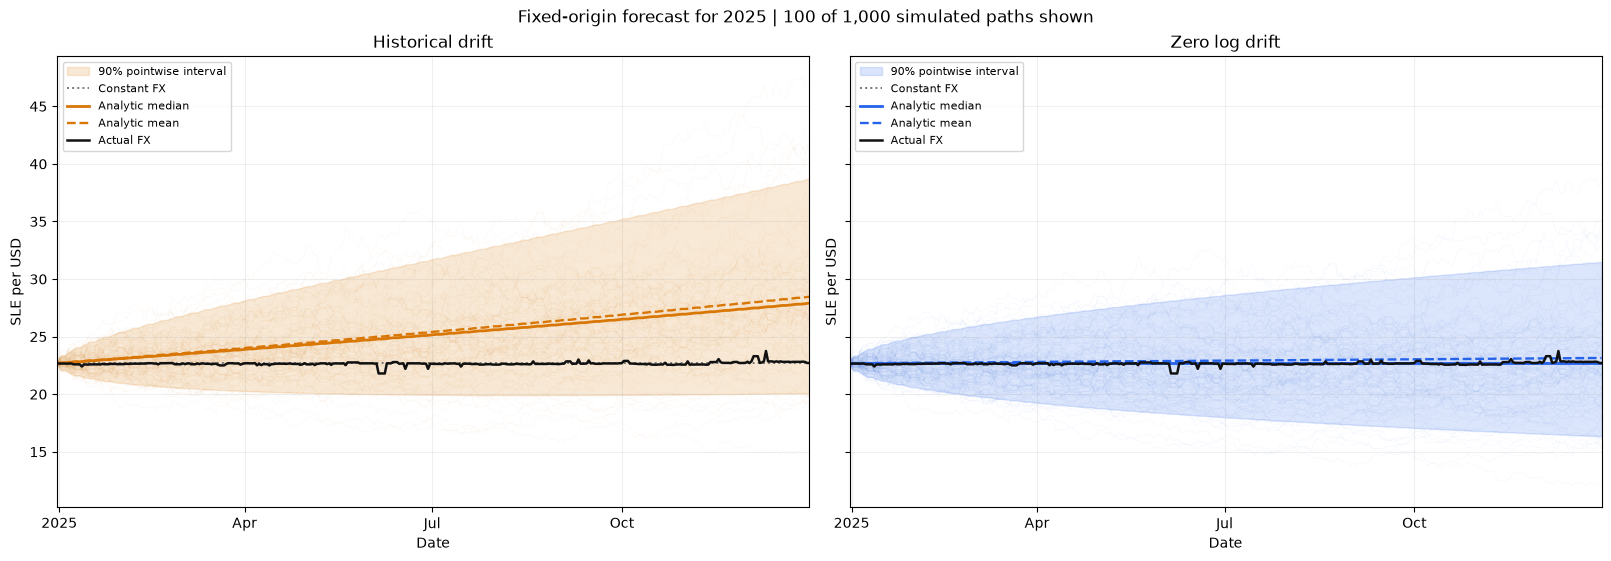

In [20]:
bt_colors = {"Historical drift": "#D97706", "Zero log drift": "#2563EB"}
bt_fig_paths, bt_axes_paths = plt.subplots(
    1, 2, figsize=(16, 5.5), sharey=True, layout="constrained"
)
for bt_ax, (bt_model, bt_band) in zip(bt_axes_paths, bt_distribution.items()):
    bt_color = bt_colors[bt_model]
    bt_ax.plot(
        bt_path_dates, bt_paths[bt_model].iloc[:, :100].to_numpy(),
        color=bt_color, alpha=0.045, linewidth=0.5,
    )
    bt_ax.fill_between(
        bt_path_dates, bt_band["lower"], bt_band["upper"],
        color=bt_color, alpha=0.16, label="90% pointwise interval",
    )
    bt_ax.axhline(
        bt_initial_fx, color="#777777", linestyle=":", linewidth=1.4,
        label="Constant FX",
    )
    bt_ax.plot(
        bt_path_dates, bt_band["median"],
        color=bt_color, linewidth=2, label="Analytic median",
    )
    bt_ax.plot(
        bt_path_dates, bt_band["mean"],
        color=bt_color, linestyle="--", linewidth=1.7, label="Analytic mean",
    )
    bt_ax.plot(
        bt_actual_with_origin.index, bt_actual_with_origin.to_numpy(),
        color="#111111", linewidth=1.8, label="Actual FX",
    )
    bt_ax.set(
        title=bt_model, xlabel="Date", ylabel="SLE per USD",
        xlim=(BT_ORIGIN, BT_END),
    )
    bt_locator = mdates.AutoDateLocator(minticks=4, maxticks=6)
    bt_ax.xaxis.set_major_locator(bt_locator)
    bt_ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(bt_locator))
    bt_ax.grid(alpha=0.2)
    bt_ax.legend(fontsize=8, loc="upper left")
bt_fig_paths.suptitle(
    "Fixed-origin forecast for 2025 | 100 of 1,000 simulated paths shown"
)
plt.show()


然后，对 2025 年每一天计算“预测汇率减实际汇率”，再汇总全年：

- **MAE**：每日绝对误差的平均值。
- **RMSE**：先将误差平方并取平均，再开平方。较大的误差会得到更高的权重。
- 两者单位均为 **SLE per USD**，数值越小，点预测越接近实际。

两种模型的均值和中位数都参与评分，并与恒定汇率基准比较。RMSE_gain_vs_constant_pct 为相对基准的 RMSE 改善百分比，正数表示改善，负数表示变差。

Then, for each day in 2025, calculate “forecast exchange rate minus actual exchange rate,” and aggregate over the full year:

- **MAE**: the average of the daily absolute errors.
- **RMSE**: first square the errors and take the average, then take the square root. Larger errors receive higher weight.
- Both are measured in **SLE per USD**; the smaller the value, the closer the point forecast is to the actual value.

The mean and median of both models are included in scoring and compared with the constant exchange rate benchmark. `RMSE_gain_vs_constant_pct` is the percentage improvement in RMSE relative to the benchmark; a positive value indicates improvement, and a negative value indicates deterioration.

最后展示的误差表和柱状图，用于回答均值或中位数是否接近实际。零漂移中位数与恒定基准的误差相同。

The error table and bar chart shown at the end are used to determine whether the mean or the median is closer to the actual values. The zero-drift median has the same error as the constant benchmark.

,RMSE,MAE,RMSE_gain_vs_constant_pct
point_forecast,,,
Historical drift (mean),3.250580,2.815248,-1999.919076
Historical drift (median),2.943647,2.553704,-1801.636441
Zero log drift (mean),0.310512,0.267970,-100.595036
Zero log drift (median),0.154795,0.089425,0.000000
Constant FX,0.154795,0.089425,0.000000


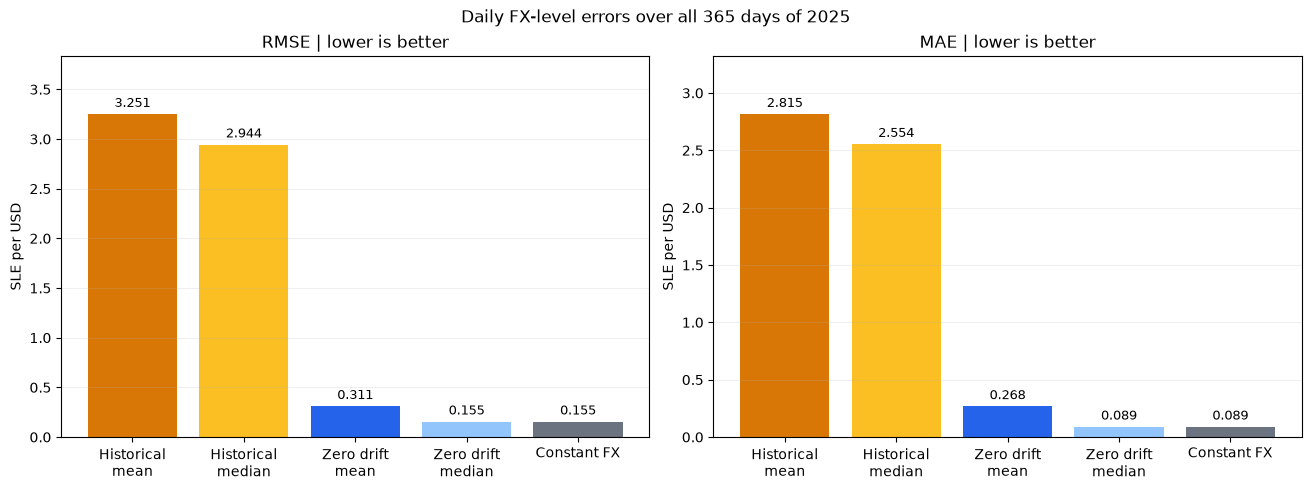

In [21]:
bt_point_forecasts = pd.DataFrame({
    f"{bt_model} ({bt_stat})": bt_band.loc[bt_dates, bt_stat]
    for bt_model, bt_band in bt_distribution.items()
    for bt_stat in ["mean", "median"]
})
bt_point_forecasts["Constant FX"] = bt_constant_forecast
bt_point_errors = bt_point_forecasts.sub(bt_actual, axis=0)
bt_point_scores = pd.DataFrame({
    "RMSE": np.sqrt(bt_point_errors.pow(2).mean()),
    "MAE": bt_point_errors.abs().mean(),
})
bt_constant_rmse = float(bt_point_scores.loc["Constant FX", "RMSE"])
bt_point_scores["RMSE_gain_vs_constant_pct"] = (
    100 * (1 - bt_point_scores["RMSE"] / bt_constant_rmse)
    if bt_constant_rmse > 0 else np.nan
)
bt_point_scores.index.name = "point_forecast"
display(bt_point_scores.round(6))

bt_point_labels = [
    "Historical\nmean", "Historical\nmedian",
    "Zero drift\nmean", "Zero drift\nmedian", "Constant FX",
]
bt_point_colors = ["#D97706", "#FBBF24", "#2563EB", "#93C5FD", "#6B7280"]
bt_fig_errors, bt_axes_errors = plt.subplots(
    1, 2, figsize=(13, 4.8), layout="constrained"
)
for bt_ax, bt_metric in zip(bt_axes_errors, ["RMSE", "MAE"]):
    bt_bars = bt_ax.bar(
        bt_point_labels, bt_point_scores[bt_metric].to_numpy(),
        color=bt_point_colors,
    )
    bt_ax.bar_label(bt_bars, fmt="%.3f", padding=3, fontsize=9)
    bt_ax.set(
        title=f"{bt_metric} | lower is better", ylabel="SLE per USD",
        ylim=(0, max(float(bt_point_scores[bt_metric].max()) * 1.18, 0.01)),
    )
    bt_ax.grid(axis="y", alpha=0.2)
bt_fig_errors.suptitle("Daily FX-level errors over all 365 days of 2025")
plt.show()


**预测区间：覆盖率、宽度和区间评分 | Prediction interval: coverage rate, width and interval score**

下面的表与示例图分别展示：
- **覆盖率**：全年有多少比例的实际汇率落在当日上下界之间。
- **平均宽度**：每天“上界减下界”的平均值。较宽的区间通常更容易覆盖实际值。
- **平均区间评分（interval score）**：以区间宽度为基础；实际值低于下界或高于上界时，再按越界距离增加惩罚。90% 区间的越界惩罚系数为 \(2/(1-0.90)=20\)。这个评分越低越好，可以同时考虑宽度和遗漏实际值的代价。

The table and example chart below respectively show:

- **Coverage**: the proportion of actual exchange rates over the full year that fall between the daily lower and upper bounds.
- **Average width**: the daily average of “upper bound minus lower bound.” Wider intervals are generally more likely to cover the actual values.
- **Average interval score**: based on the interval width; when the actual value falls below the lower bound or above the upper bound, a penalty is added according to the exceedance distance. The exceedance penalty coefficient for a 90% interval is \(2/(1-0.90)=20\). A lower score is better, as it accounts for both width and the cost of missing the actual value.

,nominal_coverage_pct,observed_coverage_pct,covered_days,below_interval_days,above_interval_days,mean_width_SLE_per_USD,mean_interval_score
model,,,,,,,
Historical drift,90.0,100.0,365,0,0,11.3928,11.3928
Zero log drift,90.0,100.0,365,0,0,10.0457,10.0457


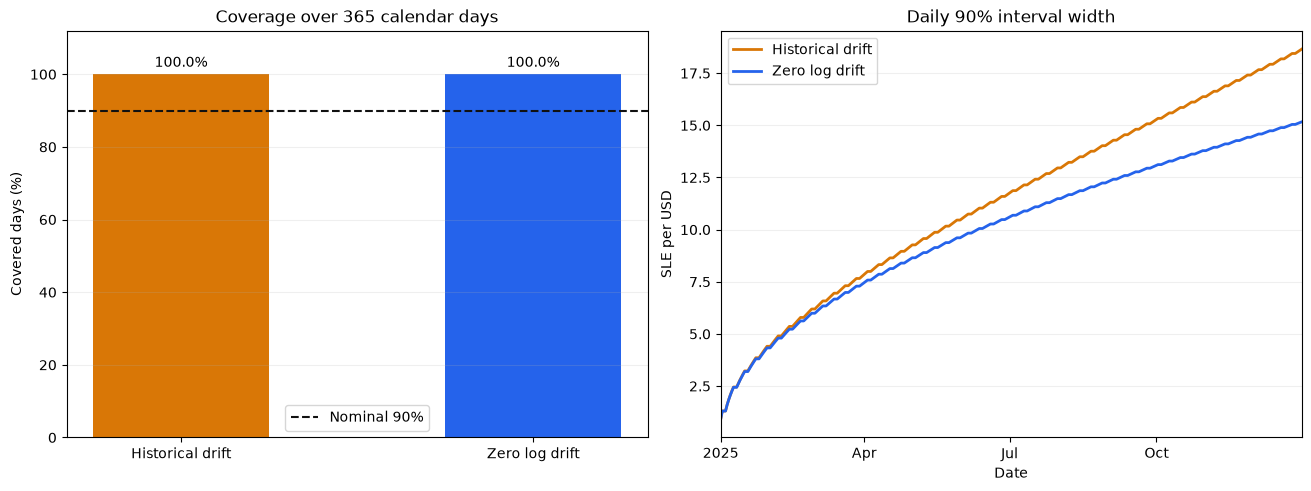

In [22]:
bt_interval_daily = {}
bt_interval_rows = []
for bt_model, bt_band in bt_distribution.items():
    bt_lower = bt_band.loc[bt_dates, "lower"]
    bt_upper = bt_band.loc[bt_dates, "upper"]
    bt_width = bt_upper - bt_lower
    bt_below = bt_actual.lt(bt_lower)
    bt_above = bt_actual.gt(bt_upper)
    bt_inside = ~(bt_below | bt_above)
    bt_interval_score = (
        bt_width
        + (2 / bt_alpha) * (bt_lower - bt_actual).clip(lower=0)
        + (2 / bt_alpha) * (bt_actual - bt_upper).clip(lower=0)
    )
    bt_interval_daily[bt_model] = pd.DataFrame({
        "covered": bt_inside, "width": bt_width,
        "interval_score": bt_interval_score,
    })
    bt_interval_rows.append({
        "model": bt_model,
        "nominal_coverage_pct": 100 * BT_INTERVAL_LEVEL,
        "observed_coverage_pct": 100 * bt_inside.mean(),
        "covered_days": int(bt_inside.sum()),
        "below_interval_days": int(bt_below.sum()),
        "above_interval_days": int(bt_above.sum()),
        "mean_width_SLE_per_USD": bt_width.mean(),
        "mean_interval_score": bt_interval_score.mean(),
    })
bt_interval_scores = pd.DataFrame(bt_interval_rows).set_index("model")
display(bt_interval_scores.round(4))

bt_fig_intervals, bt_axes_intervals = plt.subplots(
    1, 2, figsize=(13, 4.8), layout="constrained"
)
bt_coverage_bars = bt_axes_intervals[0].bar(
    list(bt_distribution),
    bt_interval_scores["observed_coverage_pct"].to_numpy(),
    color=list(bt_colors.values()), width=0.5,
)
bt_axes_intervals[0].bar_label(bt_coverage_bars, fmt="%.1f%%", padding=3)
bt_axes_intervals[0].axhline(
    100 * BT_INTERVAL_LEVEL, color="#111111", linestyle="--",
    label="Nominal 90%",
)
bt_axes_intervals[0].set(
    title="Coverage over 365 calendar days", ylabel="Covered days (%)",
    ylim=(0, 112),
)
bt_axes_intervals[0].legend()
for bt_model, bt_daily in bt_interval_daily.items():
    bt_axes_intervals[1].plot(
        bt_dates, bt_daily["width"], color=bt_colors[bt_model],
        linewidth=2, label=bt_model,
    )
bt_axes_intervals[1].set(
    title="Daily 90% interval width", xlabel="Date", ylabel="SLE per USD",
    xlim=(bt_dates.min(), BT_END),
)
bt_width_locator = mdates.AutoDateLocator(minticks=4, maxticks=6)
bt_axes_intervals[1].xaxis.set_major_locator(bt_width_locator)
bt_axes_intervals[1].xaxis.set_major_formatter(
    mdates.ConciseDateFormatter(bt_width_locator)
)
bt_axes_intervals[1].legend()
for bt_ax in bt_axes_intervals:
    bt_ax.grid(axis="y", alpha=0.2)
plt.show()
